ÉTAPE 1 : Importation modèle InceptionV3 

On charge le modèle pré-entrainté sur ImageNet et on retire les couches fully connected pour retirer les prédictions et mettre les notres. 

In [107]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dropout

# Charger InceptionV3 sans la dernière couche (include_top=False)
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))


ÉTAPE 2 : Ajouter nos propres couches de classification 

In [108]:
x = base_model.output
x = GlobalAveragePooling2D()(x)  # Convertit la feature map 8x8x2048 en vecteur 1D
x = Dense(1024, activation='relu')(x)  # Couche dense avec 1024 neurones fully connected
x = Dropout(0.5)(x) # Dropout pour éviter le surapprentissage
predictions = Dense(3, activation='softmax')(x)  # Couche de sortie pour 3 classes

model = Model(inputs=base_model.input, outputs=predictions)

ÉTAPE 3 : Gèle des couches d'InceptionV3

On gèle les couches pré-entrainées pour garder les connaissances de notre modèle.

In [109]:
for layer in base_model.layers:
    layer.trainable = False  # Geler les couches de base pour le transfert learning

ÉTAPE 4 : Préparation de nos données

In [ ]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.inception_v3 import preprocess_input

# Chemins vers les répertoires d'entraînement, de train et de validation
train_dir = os.path.join(os.getcwd(), 'chest_xray', 'train') 
val_dir = os.path.join(os.getcwd(), 'chest_xray', 'val') 

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,       # rotation aléatoire jusqu'à 10 degrés
    width_shift_range=0.1,   # décalage horizontal aléatoire jusqu'à 5%
    height_shift_range=0.1,  # décalage vertical aléatoire jusqu'à 5%
    zoom_range=0.15,          # zoom aléatoire jusqu'à 10%
    horizontal_flip=True,    # retournement horizontal aléatoire
    fill_mode='nearest'      # mode de remplissage pour les pixels manquants
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 5216 images belonging to 3 classes.
Found 36 images belonging to 3 classes.


ÉTAPE 5: Complier et entraîner le modèle

In [111]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', Precision(), Recall()])
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
checkpoint = ModelCheckpoint("best_model.h5", monitor="val_accuracy", save_best_only=True)
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

# Entraîner le modèle
model.fit(
    train_generator,
    epochs=10,  # Ajuster le nombre d'époques selon les besoins
    # steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=val_generator,
    callbacks=[early_stop, checkpoint, lr_scheduler]
    # validation_steps=val_generator.samples // val_generator.batch_size,
)

/Users/yannplouhinec/Library/Python/3.9/lib/python/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 835ms/step - accuracy: 0.6029 - loss: 1.2401 - precision_6: 0.6286 - recall_6: 0.5622

163/163 ━━━━━━━━━━━━━━━━━━━━ 141s 847ms/step - accuracy: 0.6034 - loss: 1.2376 - precision_6: 0.6291 - recall_6: 0.5626 - val_accuracy: 0.3611 - val_loss: 1.0709 - val_precision_6: 0.3448 - val_recall_6: 0.2778 - learning_rate: 0.0010
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 852ms/step - accuracy: 0.7359 - loss: 0.5936 - precision_6: 0.7600 - recall_6: 0.6968

163/163 ━━━━━━━━━━━━━━━━━━━━ 140s 859ms/step - accuracy: 0.7359 - loss: 0.5936 - precision_6: 0.7600 - recall_6: 0.6968 - val_accuracy: 0.3889 - val_loss: 1.0104 - val_precision_6: 0.4062 - val_recall_6: 0.3611 - learning_rate: 0.0010
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 859ms/step - accuracy: 0.7636 - loss: 0.5652 - precision_6: 0.7840 - recall_6: 0.7291

163/163 ━━━━━━━━━━━━━━━━━━━━ 141s 866ms/step - accuracy: 0.7635 - loss: 0.5651 - precision_6: 0.7840 - recall_6: 0.7292 - val_accuracy: 0.4167 - val_loss: 1.0825 - val_precision_6: 0.4286 - val_recall_6: 0.4167 - learning_rate: 0.0010
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 860ms/step - accuracy: 0.7648 - loss: 0.5415 - precision_6: 0.7882 - recall_6: 0.7378
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
163/163 ━━━━━━━━━━━━━━━━━━━━ 141s 866ms/step - accuracy: 0.7648 - loss: 0.5415 - precision_6: 0.7882 - recall_6: 0.7378 - val_accuracy: 0.3333 - val_loss: 1.1187 - val_precision_6: 0.3448 - val_recall_6: 0.2778 - learning_rate: 0.0010
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 141s 861ms/step - accuracy: 0.7811 - loss: 0.5121 - precision_6: 0.7921 - recall_6: 0.7515 - val_accuracy: 0.3889 - val_loss: 0.9630 - val_precision_6: 0.4062 - val_recall_6: 0.3611 - learning_rate: 5.0000e-04
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 140s 857ms/step - accuracy: 0.7818 

In [112]:
train_eval_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Important pour la correspondance entre y_pred et y_true
)


Found 5216 images belonging to 3 classes.


In [113]:
import numpy as np

y_train_pred = model.predict(train_eval_generator)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)
y_train_true = train_eval_generator.classes

y_val_pred = model.predict(val_generator)
y_val_true = val_generator.classes

163/163 ━━━━━━━━━━━━━━━━━━━━ 142s 868ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 690ms/step


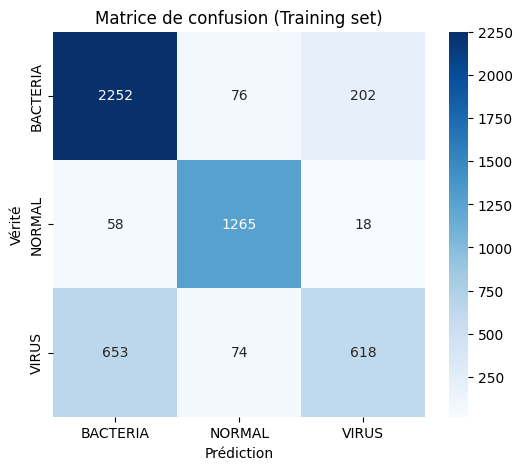

Rapport de classification sur le set d'entraînement :


In [114]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

cm_train = confusion_matrix(y_train_true, y_train_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', xticklabels=train_eval_generator.class_indices,
            yticklabels=train_eval_generator.class_indices)
plt.title('Matrice de confusion (Training set)')
plt.xlabel('Prédiction')
plt.ylabel('Vérité')
plt.show()

print("Rapport de classification sur le set d'entraînement :")
#print(classification_report(y_train_true, y_train_pred_classes, target_names=train_eval_generator.class_indices))


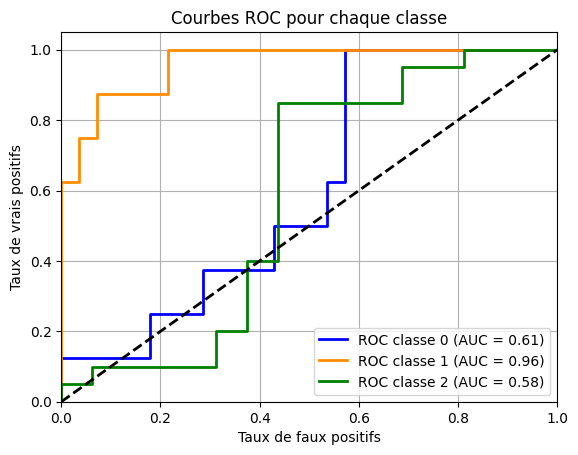

In [115]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Binarisation des vraies classes
y_val_true_bin = label_binarize(y_val_true, classes=[0, 1, 2])  # 3 classes

# Initialisation
fpr = dict()
tpr = dict()
roc_auc = dict()

# Pour chaque classe
for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_val_true_bin[:, i], y_val_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Affichage
plt.figure()
colors = ['blue', 'darkorange', 'green']
for i, color in zip(range(3), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC classe {0} (AUC = {1:0.2f})'.format(i, roc_auc[i]))
    
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbes ROC pour chaque classe')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


Étape 6 : Fine-tuning

In [116]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import AUC

for layer in base_model.layers[-10:]:
    layer.trainable = True

model.compile(optimizer=Adam(learning_rate=1e-5),
              loss='categorical_crossentropy',
              metrics=['accuracy', Precision(), Recall(), AUC()])

# Entraîner le modèle
model.fit(
    train_generator,
    epochs=5,  # Ajuster le nombre d'époques selon les besoins
    # steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=val_generator,
    callbacks=[early_stop, checkpoint, lr_scheduler]
    # validation_steps=val_generator.samples // val_generator.batch_size,
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 147s 887ms/step - accuracy: 0.7807 - auc: 0.9232 - loss: 0.5191 - precision_7: 0.8052 - recall_7: 0.7564 - val_accuracy: 0.3889 - val_auc: 0.7143 - val_loss: 0.9733 - val_precision_7: 0.4118 - val_recall_7: 0.3889 - learning_rate: 1.0000e-05
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 147s 901ms/step - accuracy: 0.7845 - auc: 0.9270 - loss: 0.5038 - precision_7: 0.7996 - recall_7: 0.7605 - val_accuracy: 0.3889 - val_auc: 0.7141 - val_loss: 0.9980 - val_precision_7: 0.4118 - val_recall_7: 0.3889 - learning_rate: 1.0000e-05
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 869ms/step - accuracy: 0.7924 - auc: 0.9284 - loss: 0.4985 - precision_7: 0.8079 - recall_7: 0.7732
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
163/163 ━━━━━━━━━━━━━━━━━━━━ 143s 876ms/step - accuracy: 0.7924 - auc: 0.9284 - loss: 0.4985 - precision_7: 0.8079 - recall_7: 0.7732 - val_accuracy: 0.3889 - val_auc: 0.7128 - val_loss: 1.0134 - val_precision_7: 0.4118 

Bonus : Afficher la matrice de confusion et la courbe AUC/ROC 

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 700ms/step


<Figure size 600x600 with 0 Axes>

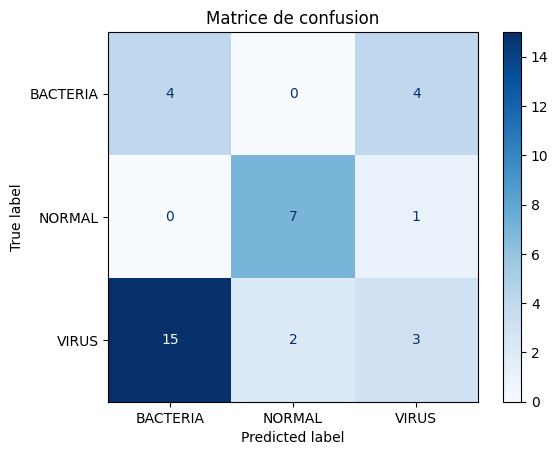

In [117]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report, roc_curve, auc, RocCurveDisplay

# Étape 1 : Prédictions sur le jeu de validation
y_pred = model.predict(val_generator)
y_pred_classes = np.argmax(y_pred, axis=1) # Indice de la classe prédite

# Étape 2 : Récupérer les vraies classes
y_true = val_generator.classes  # Classes réelles

# Étape 3 : Obtenir les noms de classes dans le bon ordre
class_names = list(val_generator.class_indices.keys())  # Noms des classes

# Étape 4 : Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_classes)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# Étape 5 : Afficher la matrice de confusion
plt.figure(figsize=(6, 6))
display.plot(cmap=plt.cm.Blues, values_format='d') # Afficher les valeurs entières ?? 
plt.title('Matrice de confusion')
plt.show()


Classification Report:

              precision    recall  f1-score   support

    BACTERIA       0.21      0.50      0.30         8
      NORMAL       0.78      0.88      0.82         8
       VIRUS       0.38      0.15      0.21        20

    accuracy                           0.39        36
   macro avg       0.45      0.51      0.44        36
weighted avg       0.43      0.39      0.37        36



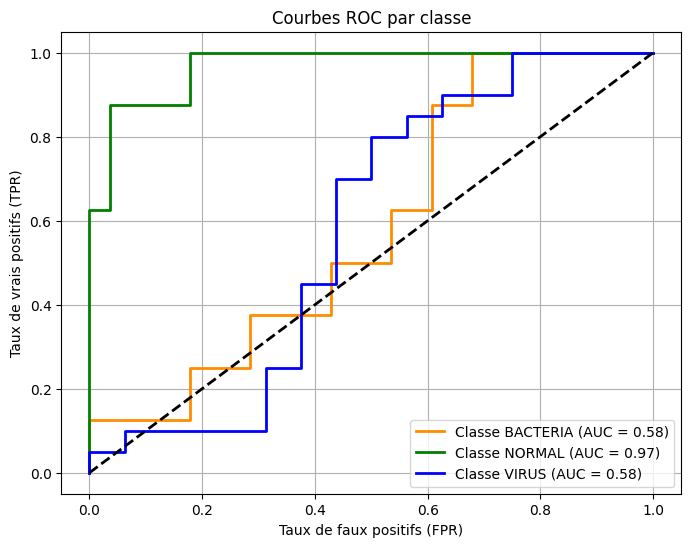

In [118]:


# Rapport de classification (précision, rappel, F1-score)
print("Classification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names))


y_true_bin = label_binarize(y_true, classes=[0, 1, 2])

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
colors = ['darkorange', 'green', 'blue', 'red']
class_labels = class_names

for i in range(3):
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2,
             label=f"Classe {class_labels[i]} (AUC = {roc_auc[i]:.2f})")
    
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.title('Courbes ROC par classe')
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.legend(loc='lower right')
plt.grid()
plt.show()

